In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [41]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/laptopData.csv')
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [42]:
df.drop(['Unnamed: 0'] , axis = 1 , inplace = True)

In [43]:
df.reset_index(drop=True , inplace=True)

In [44]:
df.describe()

,Price
count,1273.000000
mean,59955.814073
std,37332.251005
min,9270.720000
25%,31914.720000
50%,52161.120000
75%,79333.387200
max,324954.720000


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1273 non-null   object 
 1   TypeName          1273 non-null   object 
 2   Inches            1273 non-null   object 
 3   ScreenResolution  1273 non-null   object 
 4   Cpu               1273 non-null   object 
 5   Ram               1273 non-null   object 
 6   Memory            1273 non-null   object 
 7   Gpu               1273 non-null   object 
 8   OpSys             1273 non-null   object 
 9   Weight            1273 non-null   object 
 10  Price             1273 non-null   float64
dtypes: float64(1), object(10)
memory usage: 112.1+ KB


In [46]:
df.isnull().sum()

Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
dtype: int64

In [47]:
df.duplicated().sum()

58

In [48]:
df.drop_duplicates(inplace=True)

In [49]:
df.reset_index(drop=True, inplace=True)

In [50]:
df.duplicated().sum()

0

In [51]:
df.dropna(inplace=True)

In [52]:
from sklearn.impute import SimpleImputer


In [53]:
df.columns

Index(['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram',
       'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')

In [54]:
df.head(1)

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832


In [55]:
df['Inches'] = pd.to_numeric(df['Inches'], errors='coerce')

In [56]:
# imputer = SimpleImputer(strategy='most_frequent')
# for col in ['Company', 'TypeName', 'ScreenResolution', 'Cpu', 'Ram',
#             'Memory', 'Gpu', 'OpSys', 'Weight']:
#     df[[col]] = imputer.fit_transform(df[[col]])

In [57]:
df.isnull().sum()

Company             0
TypeName            0
Inches              1
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

<Axes: >

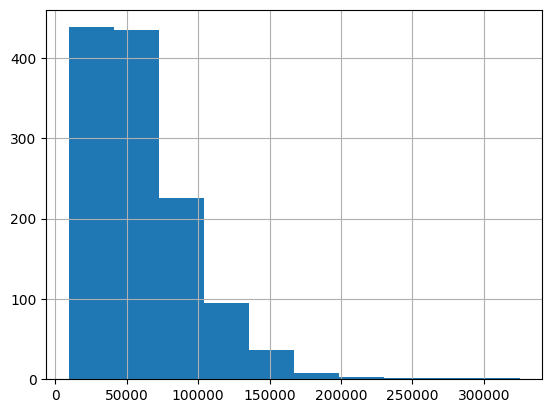

In [58]:
df['Price'].hist()

In [59]:
df['Price'].skew()

1.5199128644162267

In [60]:
imputer = SimpleImputer(strategy='median')
for col in ['Inches']:
    df[[col]] = imputer.fit_transform(df[[col]])

In [61]:
# imputer = SimpleImputer(strategy='most_frequent')
# for col in ['Company', 'TypeName', 'ScreenResolution', 'Cpu', 'Ram',
#             'Memory', 'Gpu', 'OpSys', 'Weight']:
#     df[[col]] = imputer.fit_transform(df[[col]])

In [62]:
df.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [63]:
df.select_dtypes(include=['object']).columns

Index(['Company', 'TypeName', 'ScreenResolution', 'Cpu', 'Ram', 'Memory',
       'Gpu', 'OpSys', 'Weight'],
      dtype='object')

In [64]:
import category_encoders as ce
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

for col in ['Ram', 'Weight']:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r'([0-9]+(?:\.[0-9]+)?)', expand=False),
        errors='coerce'
    )

In [65]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080


In [66]:
df[['Ram', 'Weight']] = SimpleImputer(strategy='median').fit_transform(
    df[['Ram', 'Weight']]
)

In [67]:
onehot_cols = ['Company', 'TypeName', 'OpSys']
ohe = OneHotEncoder(handle_unknown='ignore')
ohe_encoded = ohe.fit_transform(df[onehot_cols]).toarray()
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out(onehot_cols),
    index=df.index
)
df = pd.concat([df.drop(columns=onehot_cols), ohe_df], axis=1)

In [68]:
binary_cols = ['ScreenResolution', 'Cpu', 'Memory', 'Gpu']
binary_encoder = ce.BinaryEncoder(cols=binary_cols)
df = binary_encoder.fit_transform(df)

In [69]:
df.select_dtypes(include=['object']).columns

Index([], dtype='object')

In [70]:
df

,Inches,ScreenResolution_0,ScreenResolution_1,ScreenResolution_2,ScreenResolution_3,ScreenResolution_4,ScreenResolution_5,Cpu_0,Cpu_1,Cpu_2,...,TypeName_Workstation,OpSys_Android,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,13.3,0,0,0,0,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,15.6,0,0,0,0,1,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,15.4,0,0,0,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,13.3,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1240,15.6,0,0,0,1,0,1,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1241,14.0,0,0,1,0,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1242,13.3,0,1,1,1,1,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1243,14.0,0,0,0,1,0,1,1,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [71]:
df.columns

Index(['Inches', 'ScreenResolution_0', 'ScreenResolution_1',
       'ScreenResolution_2', 'ScreenResolution_3', 'ScreenResolution_4',
       'ScreenResolution_5', 'Cpu_0', 'Cpu_1', 'Cpu_2', 'Cpu_3', 'Cpu_4',
       'Cpu_5', 'Cpu_6', 'Ram', 'Memory_0', 'Memory_1', 'Memory_2', 'Memory_3',
       'Memory_4', 'Memory_5', 'Gpu_0', 'Gpu_1', 'Gpu_2', 'Gpu_3', 'Gpu_4',
       'Gpu_5', 'Gpu_6', 'Weight', 'Price', 'Company_Acer', 'Company_Apple',
       'Company_Asus', 'Company_Chuwi', 'Company_Dell', 'Company_Fujitsu',
       'Company_Google', 'Company_HP', 'Company_Huawei', 'Company_LG',
       'Company_Lenovo', 'Company_MSI', 'Company_Mediacom',
       'Company_Microsoft', 'Company_Razer', 'Company_Samsung',
       'Company_Toshiba', 'Company_Vero', 'Company_Xiaomi',
       'TypeName_2 in 1 Convertible', 'TypeName_Gaming', 'TypeName_Netbook',
       'TypeName_Notebook', 'TypeName_Ultrabook', 'TypeName_Workstation',
       'OpSys_Android', 'OpSys_Chrome OS', 'OpSys_Linux', 'OpSys_Mac OS X',
  

In [72]:
X = df.drop(['Price'] , axis=1)
X.head()

,Inches,ScreenResolution_0,ScreenResolution_1,ScreenResolution_2,ScreenResolution_3,ScreenResolution_4,ScreenResolution_5,Cpu_0,Cpu_1,Cpu_2,...,TypeName_Workstation,OpSys_Android,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,13.3,0,0,0,0,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,15.6,0,0,0,0,1,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,15.4,0,0,0,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,13.3,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [73]:
y = df['Price']
y.head()

0     71378.6832
1     47895.5232
2     30636.0000
3    135195.3360
4     96095.8080
Name: Price, dtype: float64

In [74]:
df.reset_index(drop=True, inplace=True)

In [75]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (995, 63)  y_train =  (995,)
X_test  =  (249, 63)  y_test  =  (249,)


In [76]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [77]:
y_train.head()

206    29250.72
390    16303.68
157    38787.84
41     79866.72
361    22697.28
Name: Price, dtype: float64

In [78]:
# X_test.head()

In [79]:
y_test.head()

286    39373.9200
501    44542.0800
208    49650.5664
102    71395.2000
673    16943.0400
Name: Price, dtype: float64

In [80]:
from sklearn.linear_model import LinearRegression

In [81]:
model = LinearRegression(
    fit_intercept=True,
    copy_X=True,
    n_jobs=None,
    positive=False
)

In [82]:
from sklearn.linear_model import Ridge

In [83]:
model = Ridge()

In [84]:
model.fit(X_train , y_train)

Ridge()

In [85]:
y_pred = model.predict(X_test)

In [86]:
y_pred[:5]

array([50791.65342061, 49897.32261188, 65142.86611785, 81142.06492441,
       25264.57082856])

In [87]:
from sklearn.metrics import r2_score , mean_absolute_error , mean_squared_error


In [88]:
mr2 = r2_score(y_test , y_pred)
mr2

0.7051662871048989

## Additional visualizations (laptops)

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')
lp = pd.read_csv(r'/Users/pawn/Desktop/NTI/laptopData.csv').drop(columns='Unnamed: 0')
lp['Ram_GB'] = pd.to_numeric(lp['Ram'].astype(str).str.replace('GB', ''), errors='coerce')
lp['Weight_kg'] = pd.to_numeric(lp['Weight'].astype(str).str.replace('kg', ''), errors='coerce')
lp.shape

(1303, 13)

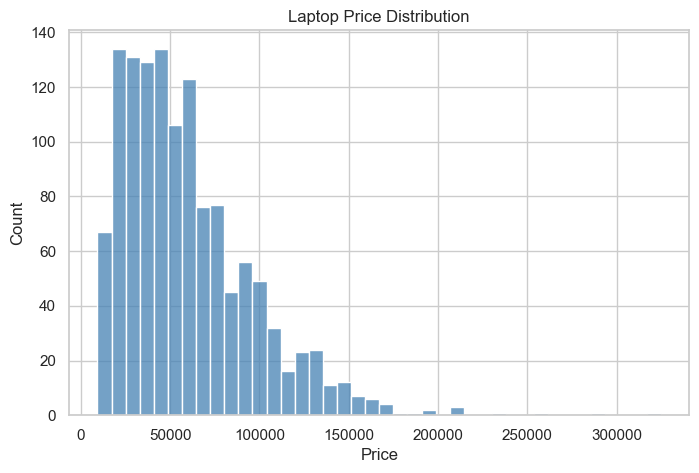

In [90]:
plt.figure(figsize=(8, 5))
sns.histplot(lp['Price'].dropna(), bins=40, color='steelblue')
plt.title('Laptop Price Distribution')
plt.show()

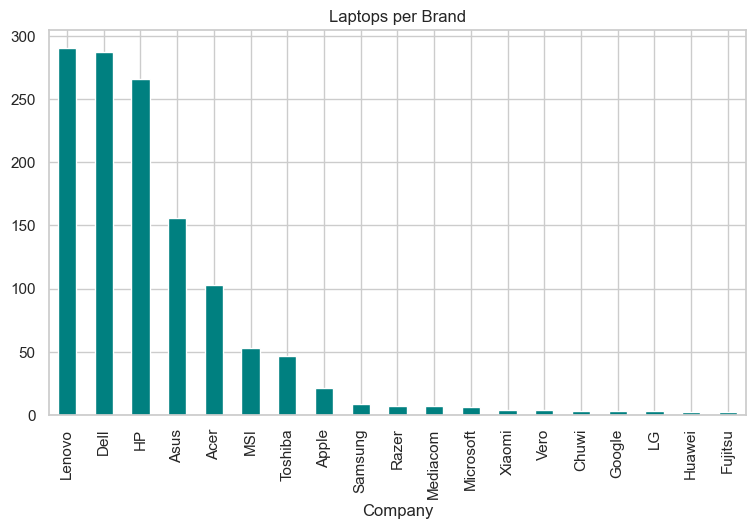

In [91]:
plt.figure(figsize=(9, 5))
lp['Company'].value_counts().plot(kind='bar', color='teal')
plt.title('Laptops per Brand')
plt.show()

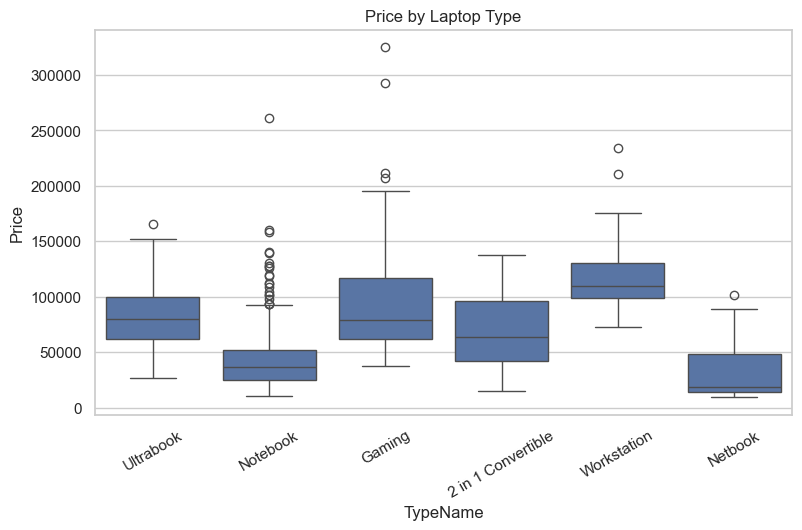

In [92]:
plt.figure(figsize=(9, 5))
sns.boxplot(x='TypeName', y='Price', data=lp)
plt.xticks(rotation=30)
plt.title('Price by Laptop Type')
plt.show()

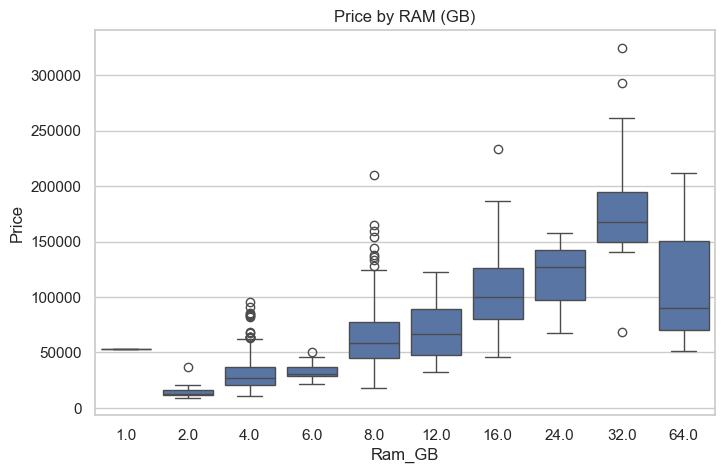

In [93]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Ram_GB', y='Price', data=lp)
plt.title('Price by RAM (GB)')
plt.show()

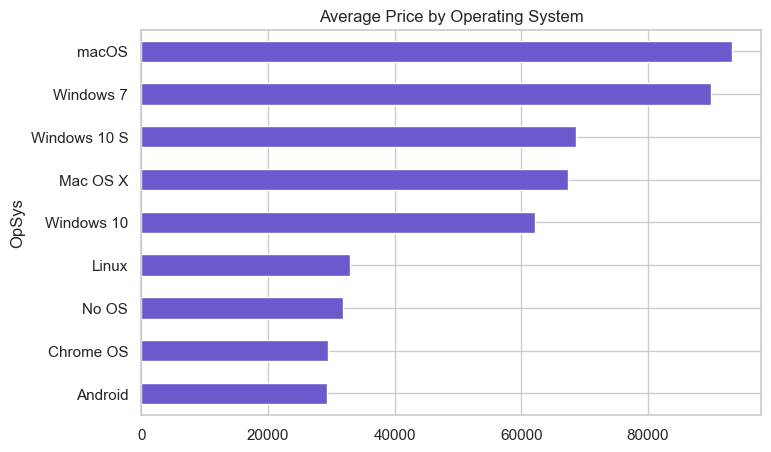

In [94]:
plt.figure(figsize=(8, 5))
lp.groupby('OpSys')['Price'].mean().sort_values().plot(kind='barh', color='slateblue')
plt.title('Average Price by Operating System')
plt.show()

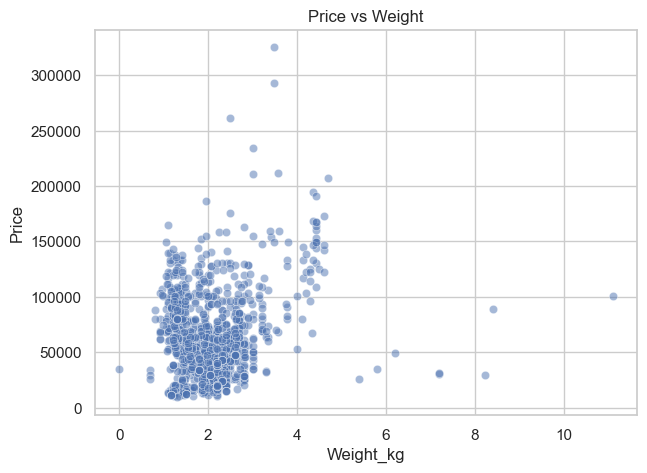

In [95]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='Weight_kg', y='Price', data=lp, alpha=0.5)
plt.title('Price vs Weight')
plt.show()

In [96]:
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/experimental/enable_hist_gradient_boosting.py:16: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [97]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [98]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

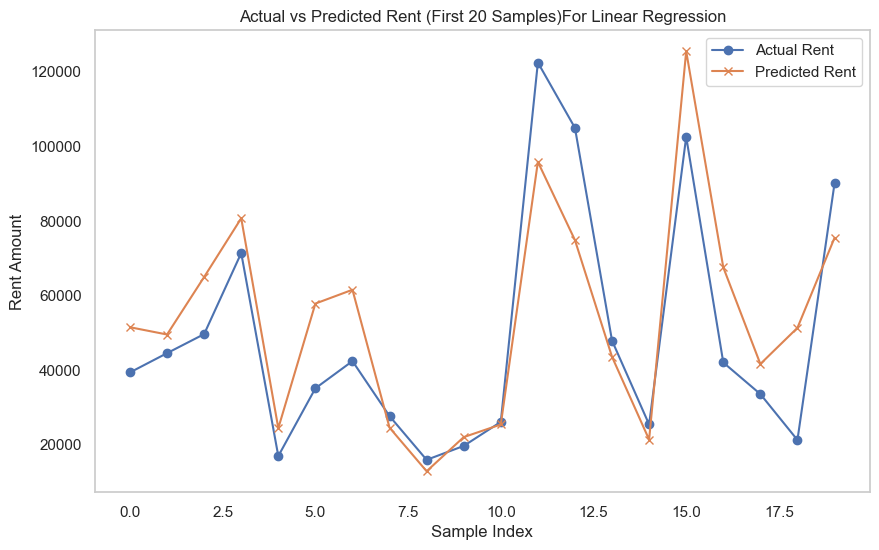

  7%|▋         | 1/15 [00:00<00:04,  2.81it/s]/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.682e+09, tolerance: 1.409e+08
  model = cd_fast.enet_coordinate_descent(


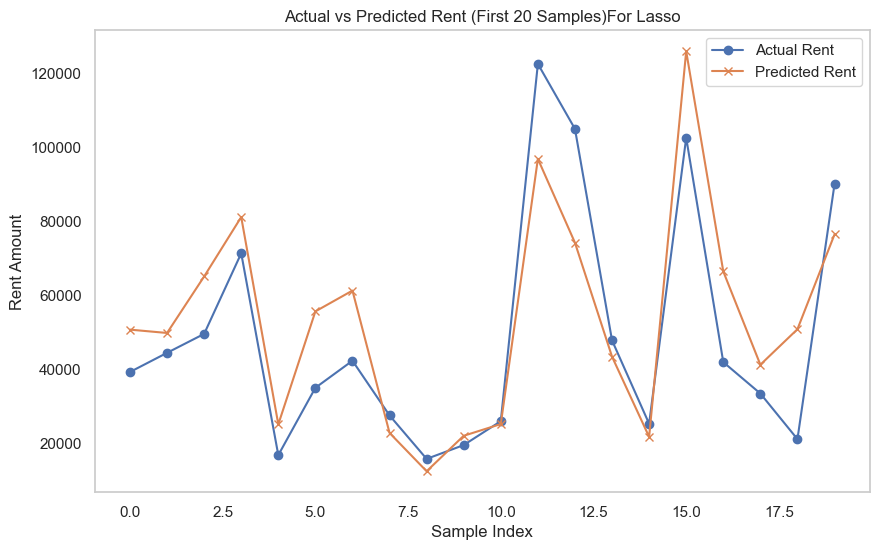

 13%|█▎        | 2/15 [00:00<00:03,  3.75it/s]

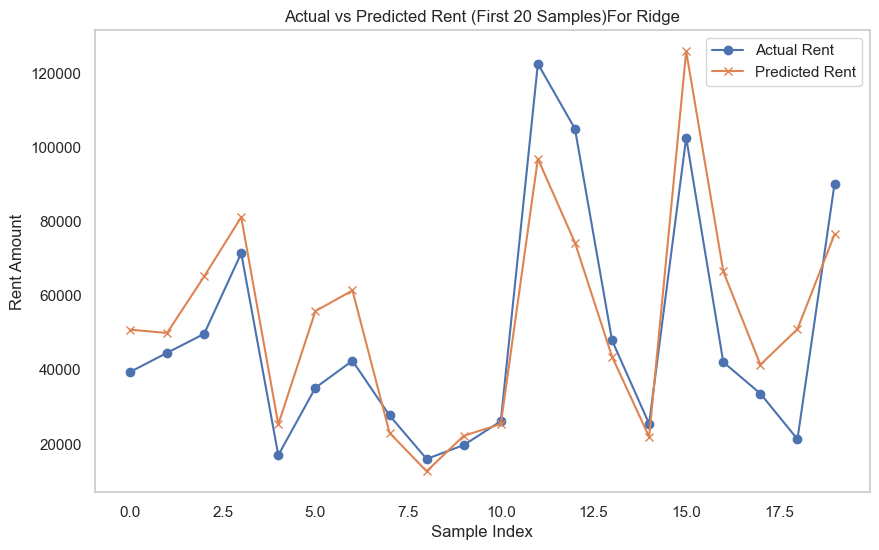

 20%|██        | 3/15 [00:00<00:02,  4.55it/s]

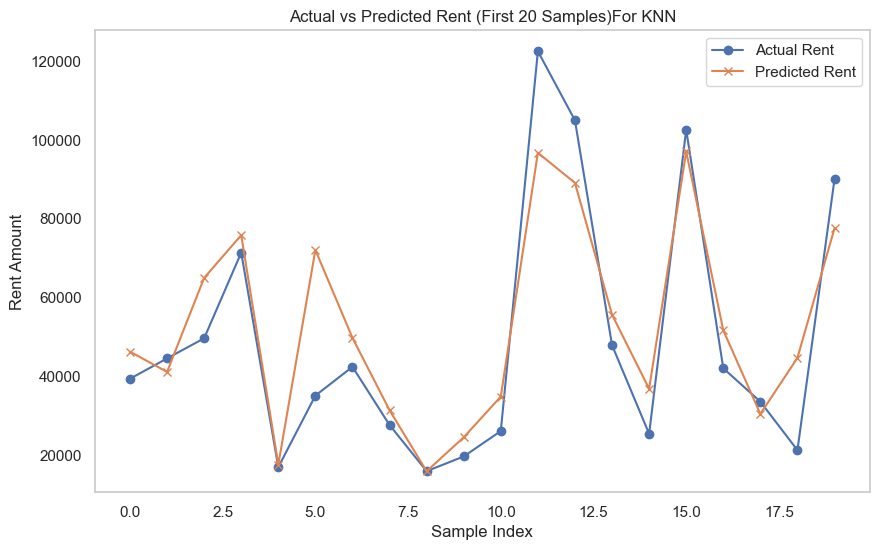

 27%|██▋       | 4/15 [00:01<00:03,  3.03it/s]

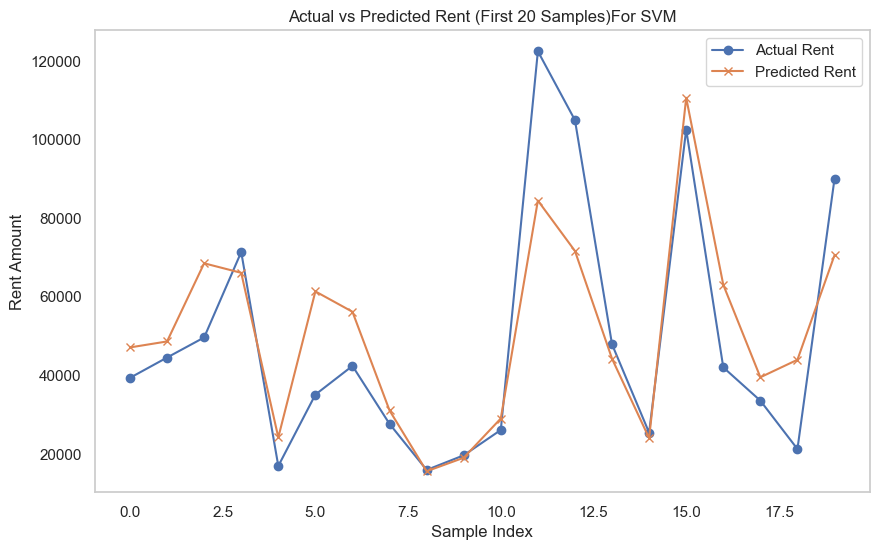

 33%|███▎      | 5/15 [00:01<00:02,  3.49it/s]

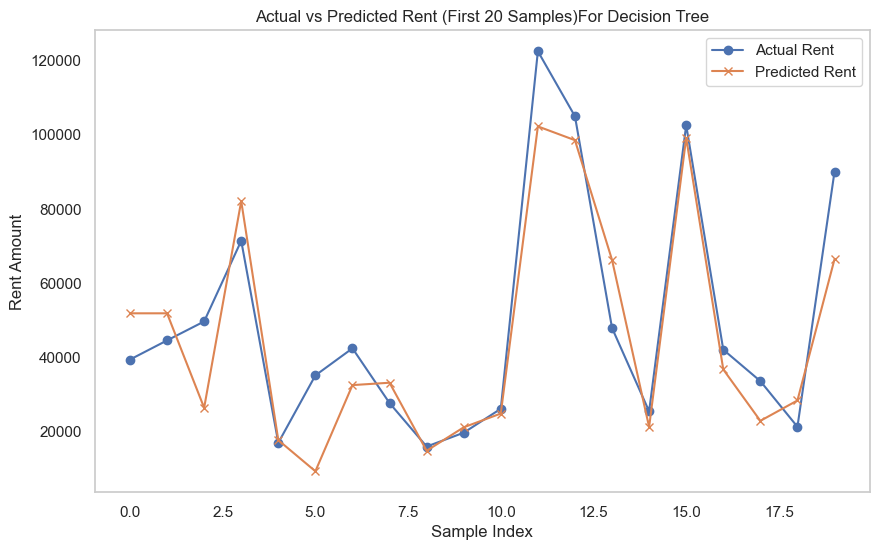

 40%|████      | 6/15 [00:01<00:02,  4.39it/s]

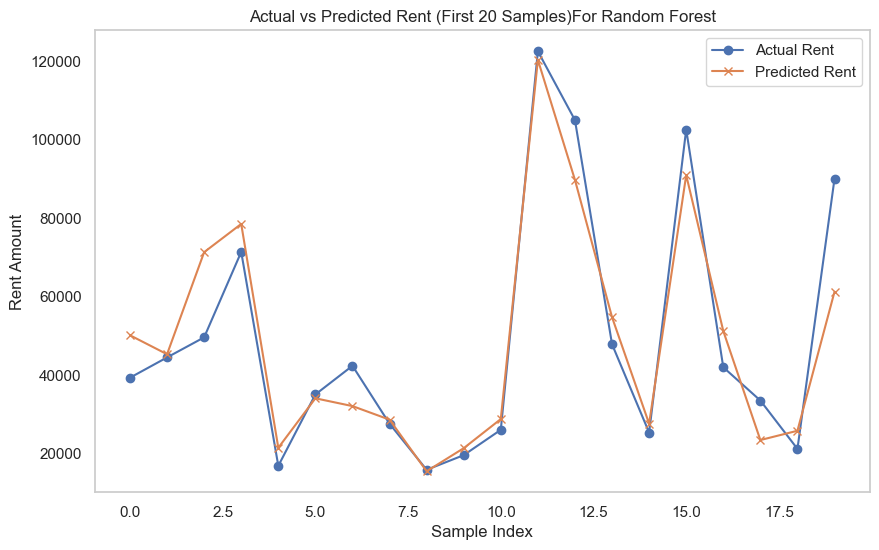

 47%|████▋     | 7/15 [00:01<00:02,  3.65it/s]

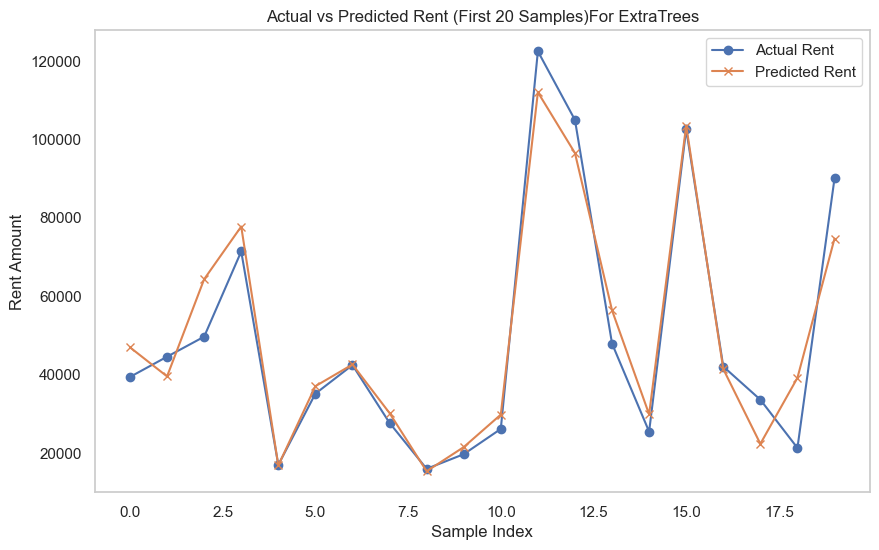

 53%|█████▎    | 8/15 [00:02<00:02,  2.56it/s]

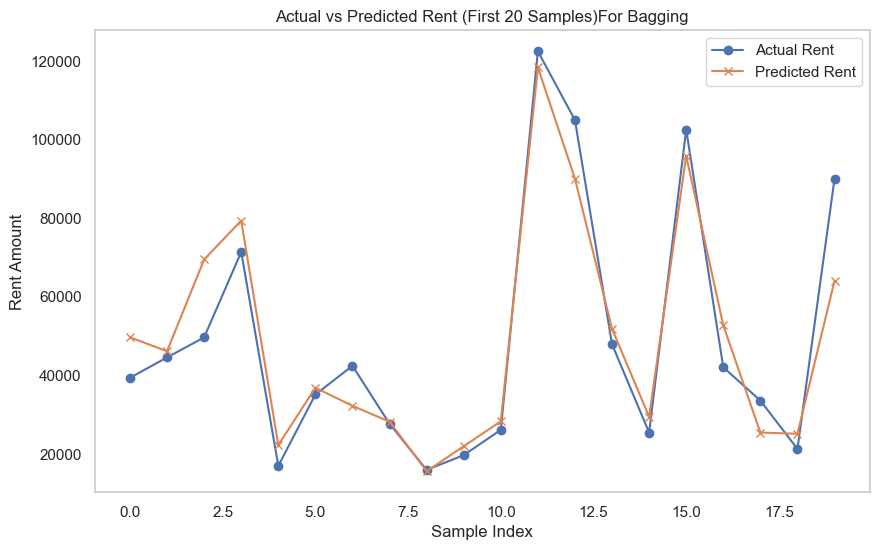

 60%|██████    | 9/15 [00:02<00:02,  2.68it/s]

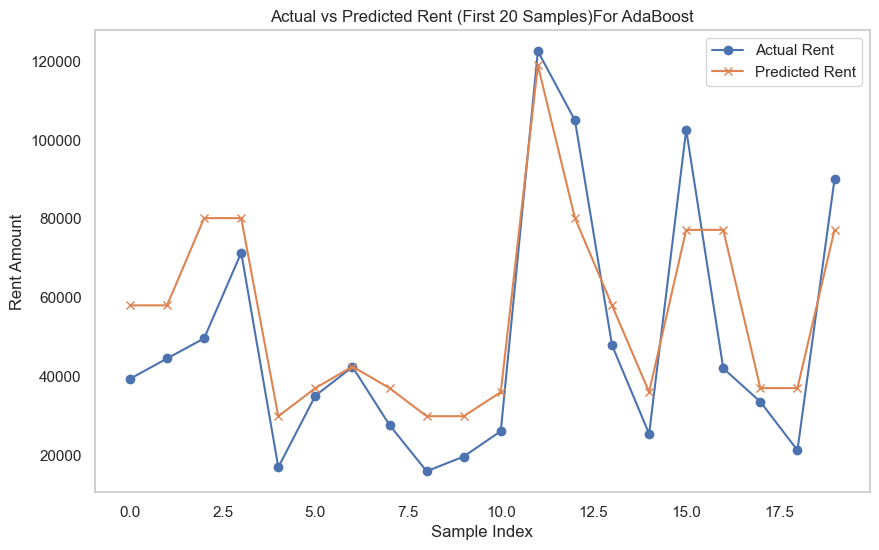

 67%|██████▋   | 10/15 [00:03<00:01,  3.31it/s]

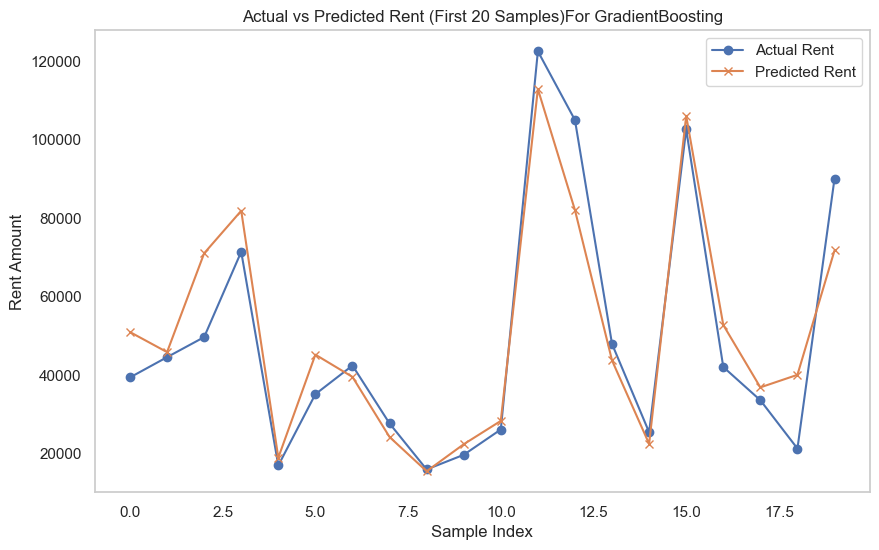

 73%|███████▎  | 11/15 [00:03<00:01,  3.60it/s]

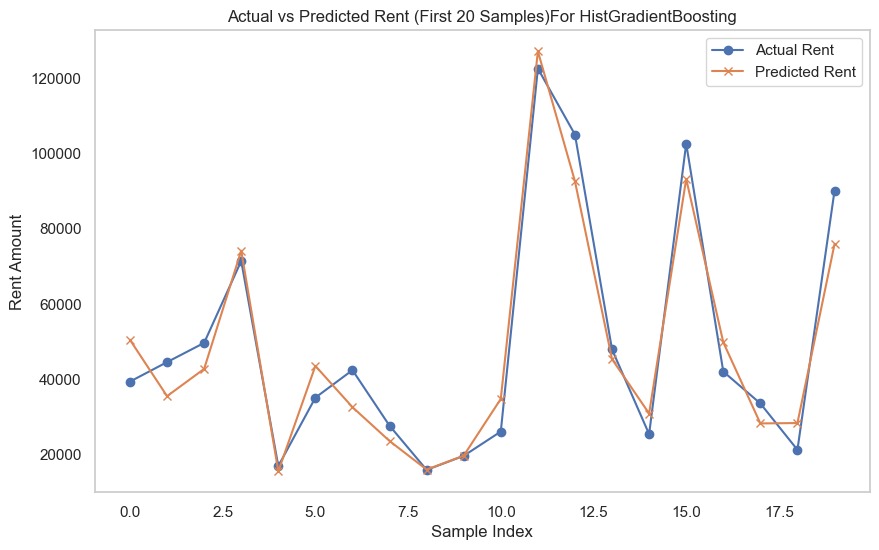

 80%|████████  | 12/15 [00:04<00:01,  1.80it/s]

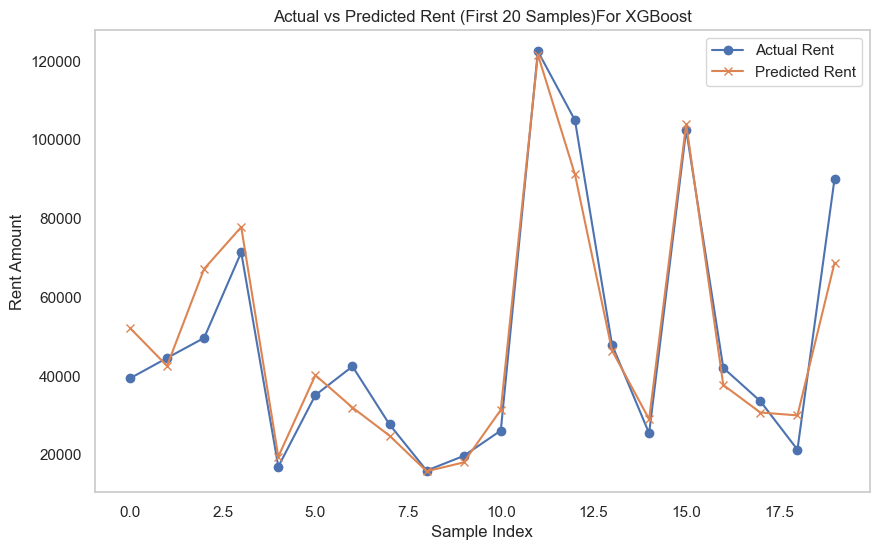

 87%|████████▋ | 13/15 [00:04<00:00,  2.01it/s]

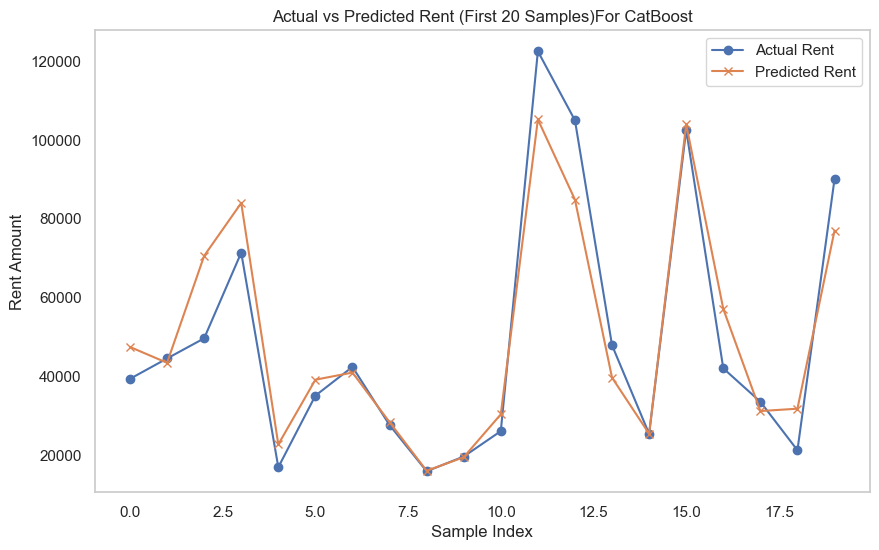

 93%|█████████▎| 14/15 [00:05<00:00,  2.25it/s]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002364 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 258
[LightGBM] [Info] Number of data points in the train set: 995, number of used features: 43
[LightGBM] [Info] Start training from score 61100.883822


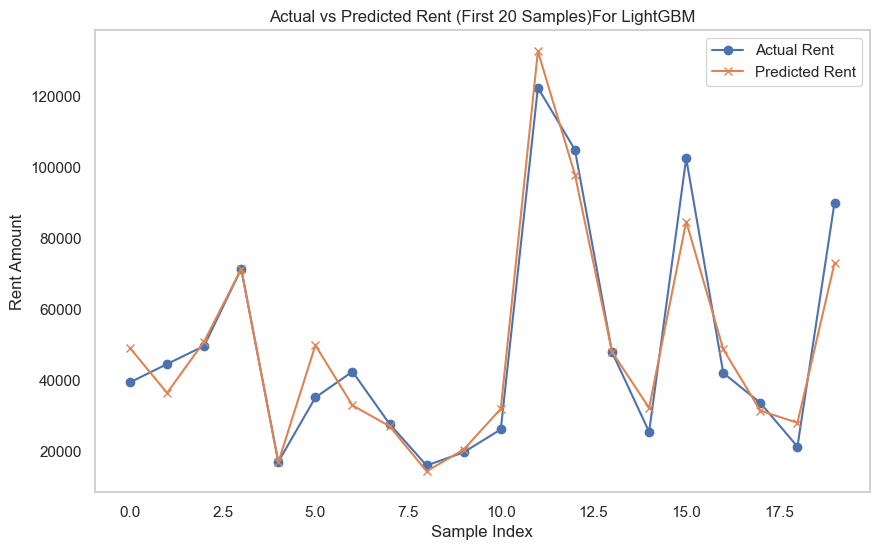

100%|██████████| 15/15 [00:05<00:00,  2.66it/s]


In [99]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [100]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [101]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001283 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 258
[LightGBM] [Info] Number of data points in the train set: 995, number of used features: 43
[LightGBM] [Info] Start training from score 61100.883822
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003398 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 240
[LightGBM] [Info] Number of data points in the train set: 796, number of used features: 42
[LightGBM] [Info] Start training from score 61003.597204
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003888 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not eno

In [102]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [103]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
LightGBM,5974.670465,10634.916629,9.113807e+07,2.823108e+08,9546.626044,16802.107663,0.935632,0.787583
HistGradientBoosting,5750.146720,10931.919864,8.432244e+07,2.879479e+08,9182.724946,16969.027834,0.940445,0.783342
CatBoost,8821.405413,11246.085567,1.415496e+08,3.038150e+08,11897.462439,17430.288314,0.900027,0.771403
XGBoost,4391.519644,10733.805059,3.844540e+07,3.081198e+08,6200.435178,17553.342757,0.972847,0.768164
Bagging,6069.310312,10815.306601,7.656196e+07,3.138627e+08,8749.969378,17716.169367,0.945926,0.763843
Random Forest,6037.984234,10788.408396,7.385886e+07,3.180360e+08,8594.118041,17833.562834,0.947835,0.760703
Stacking,5855.738794,10634.916629,8.953225e+07,2.823108e+08,9462.148029,16802.107663,0.936766,0.754995
GradientBoosting,9577.585560,11936.104369,1.647671e+08,3.303879e+08,12836.164935,18176.575994,0.883629,0.751409
Voting,5633.239067,10634.916629,6.698987e+07,2.823108e+08,8184.734115,16802.107663,0.952687,0.749797
Simple Voting,5633.239067,10634.916629,6.698987e+07,2.823108e+08,8184.734115,16802.107663,0.952687,0.749797


<Axes: >

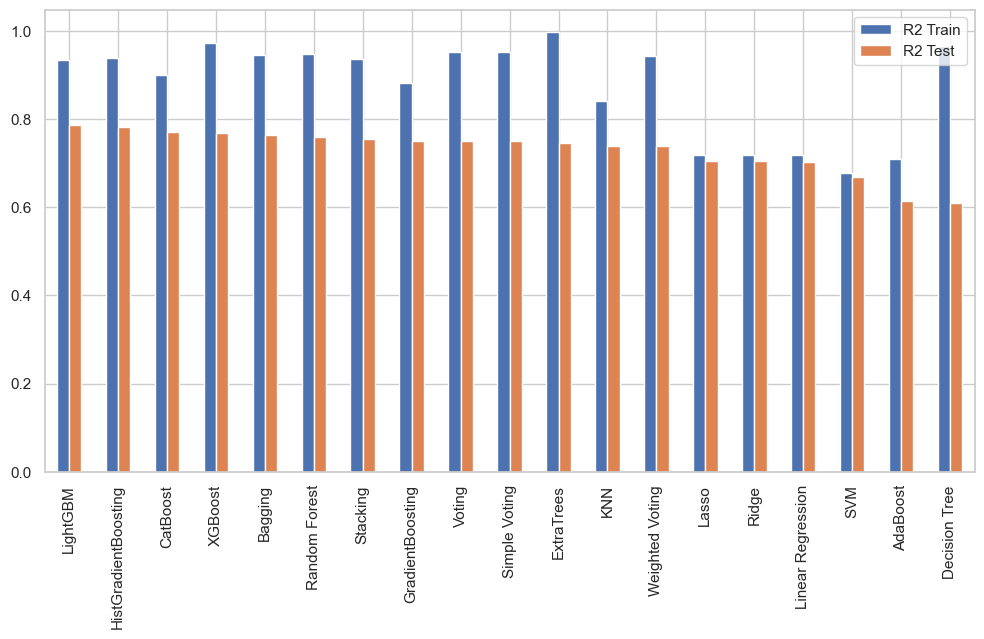

In [104]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

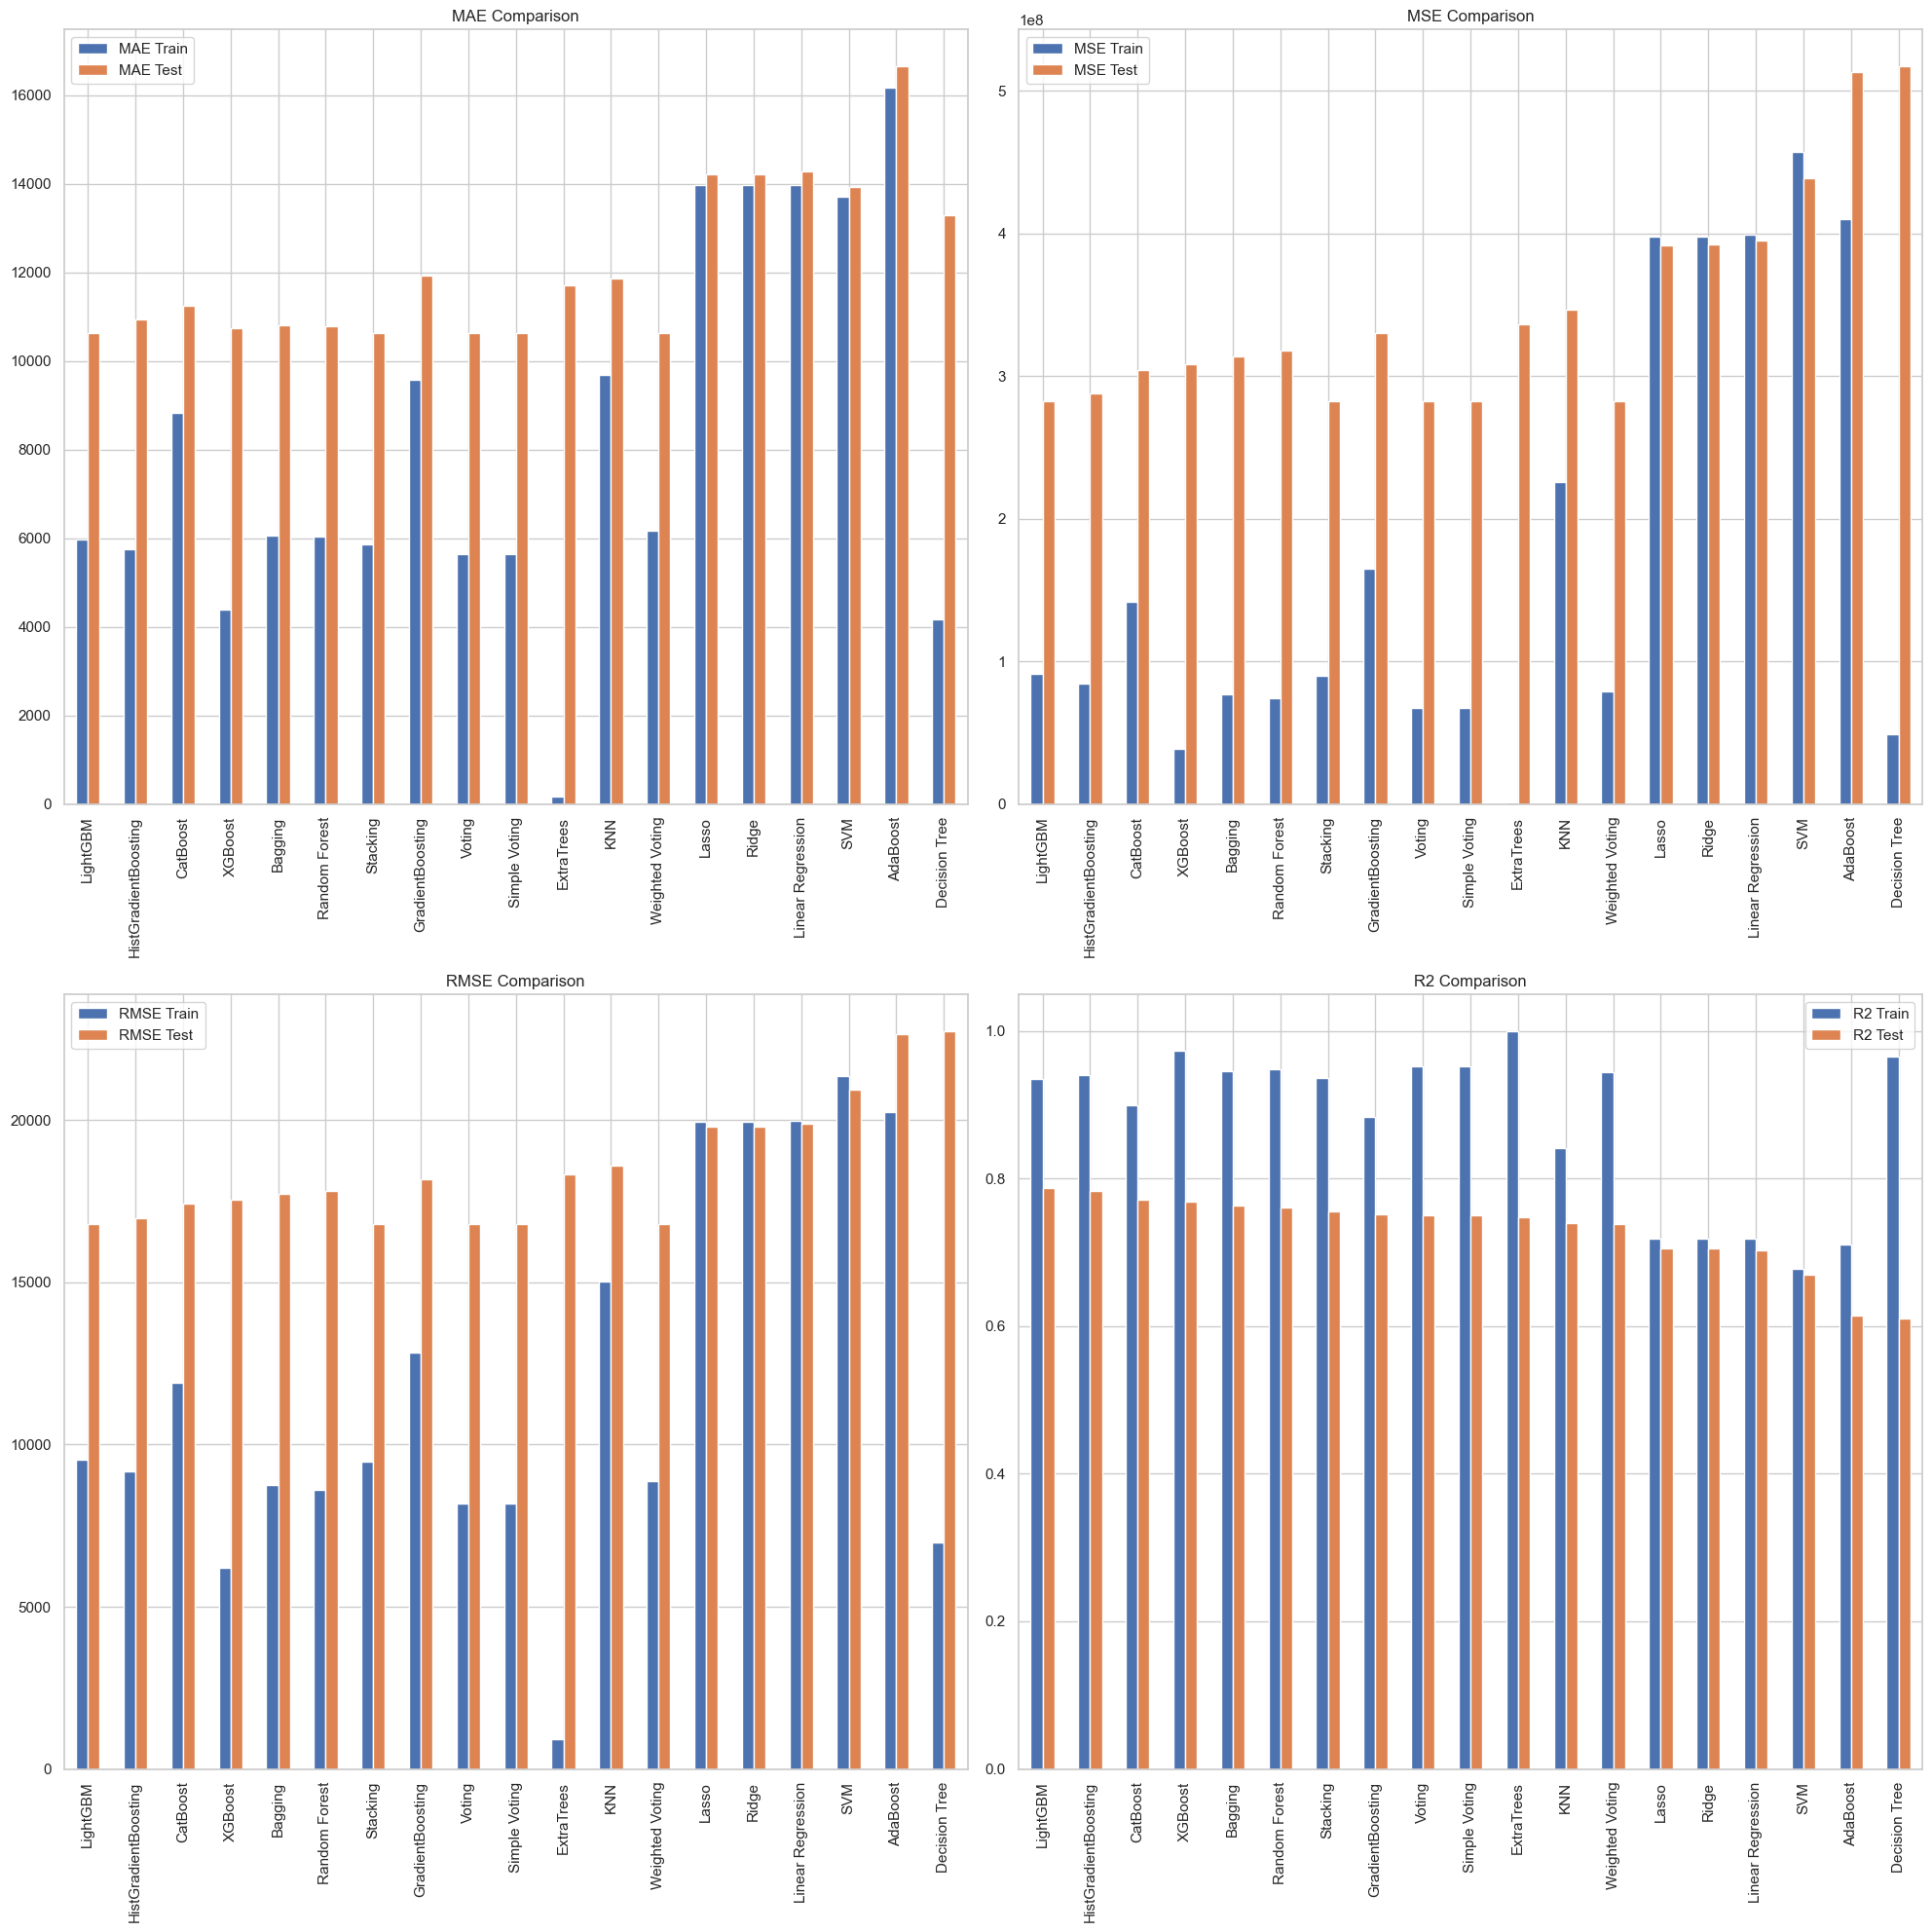

In [105]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [108]:
df.head(1)

,Inches,ScreenResolution_0,ScreenResolution_1,ScreenResolution_2,ScreenResolution_3,ScreenResolution_4,ScreenResolution_5,Cpu_0,Cpu_1,Cpu_2,...,TypeName_Workstation,OpSys_Android,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [106]:
import gradio as gr

/Users/pawn/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/pawn/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def predict(Company , 	TypeName	,Inches	,ScreenResolution	,Cpu	, Ram	, Memory	, Gpu	, OpSys	, Weight ,	Price):
    X_new = pd.DataFrame([[
        Company, TypeName, Inches, ScreenResolution, Cpu, Ram, Memory, Gpu, OpSys, Weight, Price
    ]], columns=[
        'Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'
        'age', 'insulin', 'diabetes_pedigree'
    ])

    X_new = imputer.transform(X_new)
    X_new = scaler.transform(X_new)

    prediction = best_model.predict(X_new)[0]

    return "good" if prediction == 1 else "bad"

demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Dropdown(label="Company", choices=['Dell', 'HP', 'Lenovo', 'Asus']),
        gr.Dropdown(label="TypeName", choices=['Ultrabook', 'Netbook', 'Notebook', 'Gaming']),
        gr.Number(label="Inches"),
        gr.Dropdown(label="ScreenResolution", choices=['Full HD', 'HD', 'WQHD']),
        gr.Dropdown(label="Cpu", choices=['Intel Core i3', 'Intel Core i5', 'Intel Core i7', 'AMD Ryzen 3', 'AMD Ryzen 5', 'AMD Ryzen 7']),
        gr.Dropdown(label="Ram", choices=['8 GB', '16 GB', '32 GB']),
        gr.Dropdown(label="Memory", choices=['SSD', 'HDD']),
        gr.Dropdown(label="Gpu", choices=['NVIDIA', 'AMD']),
        gr.Dropdown(label="OpSys", choices=['Windows', 'macOS', 'Linux']),
        gr.Number(label="Weight"),
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Laptop Price Prediction",
    description="Enter laptop specifications to predict the price."
)
      

demo.launch(share=True)

/Users/pawn/Library/Python/3.9/lib/python/site-packages/gradio/utils.py:1002: UserWarning: Expected 11 arguments for function <function predict at 0x142096820>, received 10.
  warnings.warn(
/Users/pawn/Library/Python/3.9/lib/python/site-packages/gradio/utils.py:1006: UserWarning: Expected at least 11 arguments for function <function predict at 0x142096820>, received 10.
  warnings.warn(


Running on local URL:  http://127.0.0.1:7861
Running on public URL: https://60c71f50e8f6b8e405.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from Terminal to deploy to Spaces (https://huggingface.co/spaces)


/Users/pawn/Library/Python/3.9/lib/python/site-packages/gradio/helpers.py:978: UserWarning: Unexpected argument. Filling with None.
  warnings.warn("Unexpected argument. Filling with None.")
Traceback (most recent call last):
  File "/Users/pawn/Library/Python/3.9/lib/python/site-packages/pandas/core/internals/construction.py", line 939, in _finalize_columns_and_data
    columns = _validate_or_indexify_columns(contents, columns)
  File "/Users/pawn/Library/Python/3.9/lib/python/site-packages/pandas/core/internals/construction.py", line 986, in _validate_or_indexify_columns
    raise AssertionError(
AssertionError: 13 columns passed, passed data had 11 columns

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/Users/pawn/Library/Python/3.9/lib/python/site-packages/gradio/queueing.py", line 536, in process_events
    response = await route_utils.call_process_api(
  File "/Users/pawn/Library/Python/3.9/lib/python/site-package